In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Define project directory
project_dir = Path.cwd()

# If the notebook is inside the notebooks folder, move to project root
if not (project_dir / "datasets" / "raw").exists():
    project_dir = project_dir.parent

# Load original Financial Risk donor dataset
donor_path = project_dir / "datasets" / "raw" / "Loan.csv"

df_donor = pd.read_csv(donor_path)

# Create a separate working copy
df_donor_clean = df_donor.copy()

print("Dataset loaded successfully!")
print("Original shape:", df_donor.shape)
print("Working copy shape:", df_donor_clean.shape)
print("Dataset path:", donor_path)

Dataset loaded successfully!
Original shape: (20000, 36)
Working copy shape: (20000, 36)
Dataset path: D:\AI-Engineering\Loan_Default_Research\datasets\raw\Loan.csv


In [2]:
# 1. Dataset dimensions
print("DATASET SHAPE:")
print(df_donor_clean.shape)

# 2. Column names
print("\nCOLUMN NAMES:")
print(df_donor_clean.columns.tolist())

# 3. Data types
print("\nDATA TYPES:")
print(df_donor_clean.dtypes)

# 4. First five records
print("\nFIRST FIVE ROWS:")
display(df_donor_clean.head())

# 5. Dataset information
print("\nDATASET INFORMATION:")
df_donor_clean.info()

DATASET SHAPE:
(20000, 36)

COLUMN NAMES:
['ApplicationDate', 'Age', 'AnnualIncome', 'CreditScore', 'EmploymentStatus', 'EducationLevel', 'Experience', 'LoanAmount', 'LoanDuration', 'MaritalStatus', 'NumberOfDependents', 'HomeOwnershipStatus', 'MonthlyDebtPayments', 'CreditCardUtilizationRate', 'NumberOfOpenCreditLines', 'NumberOfCreditInquiries', 'DebtToIncomeRatio', 'BankruptcyHistory', 'LoanPurpose', 'PreviousLoanDefaults', 'PaymentHistory', 'LengthOfCreditHistory', 'SavingsAccountBalance', 'CheckingAccountBalance', 'TotalAssets', 'TotalLiabilities', 'MonthlyIncome', 'UtilityBillsPaymentHistory', 'JobTenure', 'NetWorth', 'BaseInterestRate', 'InterestRate', 'MonthlyLoanPayment', 'TotalDebtToIncomeRatio', 'LoanApproved', 'RiskScore']

DATA TYPES:
ApplicationDate                   str
Age                             int64
AnnualIncome                    int64
CreditScore                     int64
EmploymentStatus                  str
EducationLevel                    str
Experience    

,ApplicationDate,Age,AnnualIncome,CreditScore,EmploymentStatus,EducationLevel,Experience,LoanAmount,LoanDuration,MaritalStatus,...,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,LoanApproved,RiskScore
0,2018-01-01,45,39948,617,Employed,Master,22,13152,48,Married,...,3329.000000,0.724972,11,126928,0.199652,0.227590,419.805992,0.181077,0,49.0
1,2018-01-02,38,39709,628,Employed,Associate,15,26045,48,Single,...,3309.083333,0.935132,3,43609,0.207045,0.201077,794.054238,0.389852,0,52.0
2,2018-01-03,47,40724,570,Employed,Bachelor,26,17627,36,Married,...,3393.666667,0.872241,6,5205,0.217627,0.212548,666.406688,0.462157,0,52.0
3,2018-01-04,58,69084,545,Employed,High School,34,37898,96,Single,...,5757.000000,0.896155,5,99452,0.300398,0.300911,1047.506980,0.313098,0,54.0
4,2018-01-05,37,103264,594,Employed,Associate,17,9184,36,Married,...,8605.333333,0.941369,5,227019,0.197184,0.175990,330.179140,0.070210,1,36.0



DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 36 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ApplicationDate             20000 non-null  str    
 1   Age                         20000 non-null  int64  
 2   AnnualIncome                20000 non-null  int64  
 3   CreditScore                 20000 non-null  int64  
 4   EmploymentStatus            20000 non-null  str    
 5   EducationLevel              20000 non-null  str    
 6   Experience                  20000 non-null  int64  
 7   LoanAmount                  20000 non-null  int64  
 8   LoanDuration                20000 non-null  int64  
 9   MaritalStatus               20000 non-null  str    
 10  NumberOfDependents          20000 non-null  int64  
 11  HomeOwnershipStatus         20000 non-null  str    
 12  MonthlyDebtPayments         20000 non-null  int64  
 13  CreditCardUtilizatio

In [3]:
# 1. Check missing values
print("MISSING VALUES PER COLUMN:")

missing_values = df_donor_clean.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": (
        missing_values / len(df_donor_clean) * 100
    )
})

display(
    missing_summary[
        missing_summary["Missing_Count"] > 0
    ].sort_values(
        "Missing_Count",
        ascending=False
    )
)

print("\nTOTAL MISSING CELLS:")
print(df_donor_clean.isnull().sum().sum())

# 2. Check exact duplicate records
print("\nEXACT DUPLICATE ROWS:")
print(df_donor_clean.duplicated().sum())

# 3. Check application date uniqueness
print("\nUNIQUE APPLICATION DATES:")
print(df_donor_clean["ApplicationDate"].nunique())

print("\nTOTAL RECORDS:")
print(len(df_donor_clean))

print(
    "\nIs ApplicationDate unique for every record?",
    df_donor_clean["ApplicationDate"].is_unique
)

MISSING VALUES PER COLUMN:


,Missing_Count,Missing_Percentage



TOTAL MISSING CELLS:
0

EXACT DUPLICATE ROWS:
0

UNIQUE APPLICATION DATES:
20000

TOTAL RECORDS:
20000

Is ApplicationDate unique for every record? True


In [4]:
# Check numerical ranges
numeric_summary = df_donor_clean.describe().T

display(
    numeric_summary[
        ['min', 'max', 'mean', '50%', 'std']
    ]
)

,min,max,mean,50%,std
Age,18.000000,8.000000e+01,39.752600,40.000000,11.622713
AnnualIncome,15000.000000,4.853410e+05,59161.473550,48566.000000,40350.845168
CreditScore,343.000000,7.120000e+02,571.612400,578.000000,50.997358
Experience,0.000000,6.100000e+01,17.522750,17.000000,11.316836
LoanAmount,3674.000000,1.847320e+05,24882.867800,21914.500000,13427.421217
LoanDuration,12.000000,1.200000e+02,54.057000,48.000000,24.664857
NumberOfDependents,0.000000,5.000000e+00,1.517300,1.000000,1.386325
MonthlyDebtPayments,50.000000,2.919000e+03,454.292700,402.000000,240.507609
CreditCardUtilizationRate,0.000974,9.173801e-01,0.286381,0.266673,0.159793
NumberOfOpenCreditLines,0.000000,1.300000e+01,3.023350,3.000000,1.736161


In [5]:
# Check logical and numerical validity

invalid_conditions = {
    "Age below 18": df_donor_clean["Age"] < 18,

    "Experience greater than age":
        df_donor_clean["Experience"] > df_donor_clean["Age"],

    "Job tenure greater than experience":
        df_donor_clean["JobTenure"] > df_donor_clean["Experience"],

    "Negative annual income":
        df_donor_clean["AnnualIncome"] < 0,

    "Negative monthly income":
        df_donor_clean["MonthlyIncome"] < 0,

    "Annual and monthly income mismatch":
        (
            df_donor_clean["AnnualIncome"]
            - df_donor_clean["MonthlyIncome"] * 12
        ).abs() > 1,

    "Negative loan amount":
        df_donor_clean["LoanAmount"] < 0,

    "Invalid loan duration":
        df_donor_clean["LoanDuration"] <= 0,

    "Credit score outside 300-850":
        ~df_donor_clean["CreditScore"].between(300, 850),

    "Credit utilization outside 0-1":
        ~df_donor_clean["CreditCardUtilizationRate"].between(0, 1),

    "Utility payment history outside 0-1":
        ~df_donor_clean["UtilityBillsPaymentHistory"].between(0, 1),

    "Invalid bankruptcy values":
        ~df_donor_clean["BankruptcyHistory"].isin([0, 1]),

    "Invalid previous default values":
        ~df_donor_clean["PreviousLoanDefaults"].isin([0, 1]),

    "Invalid loan approval values":
        ~df_donor_clean["LoanApproved"].isin([0, 1])
}

# Count violations for each condition
validity_summary = pd.Series(
    {
        condition: mask.sum()
        for condition, mask in invalid_conditions.items()
    },
    name="Invalid_Count"
)

display(validity_summary.to_frame())

# Count unique records affected by at least one condition
invalid_records = pd.DataFrame(invalid_conditions).any(axis=1)

print("\nTOTAL CONDITION VIOLATIONS:")
print(validity_summary.sum())

print("\nUNIQUE RECORDS WITH AT LEAST ONE ISSUE:")
print(invalid_records.sum())

print(
    "\nPERCENTAGE OF RECORDS WITH AT LEAST ONE ISSUE:",
    round(invalid_records.mean() * 100, 2),
    "%"
)

,Invalid_Count
Age below 18,0
Experience greater than age,0
Job tenure greater than experience,3098
Negative annual income,0
Negative monthly income,0
Annual and monthly income mismatch,195
Negative loan amount,0
Invalid loan duration,0
Credit score outside 300-850,0
Credit utilization outside 0-1,0



TOTAL CONDITION VIOLATIONS:
3293

UNIQUE RECORDS WITH AT LEAST ONE ISSUE:
3272

PERCENTAGE OF RECORDS WITH AT LEAST ONE ISSUE: 16.36 %


In [6]:
# Find records where job tenure exceeds total experience

tenure_issues = df_donor_clean[
    df_donor_clean['JobTenure'] > df_donor_clean['Experience']
]

print("Number of suspicious records:", len(tenure_issues))

print("\nFIRST 15 SUSPICIOUS RECORDS:")

display(
    tenure_issues[
        [
            'Age',
            'Experience',
            'JobTenure',
            'EmploymentStatus'
        ]
    ].head(15)
)

print("\nDIFFERENCE BETWEEN JOB TENURE AND EXPERIENCE:")

difference = (
    tenure_issues['JobTenure'] - tenure_issues['Experience']
)

display(difference.describe())

print("\nEMPLOYMENT STATUS OF SUSPICIOUS RECORDS:")

display(tenure_issues['EmploymentStatus'].value_counts())

Number of suspicious records: 3098

FIRST 15 SUSPICIOUS RECORDS:


,Age,Experience,JobTenure,EmploymentStatus
13,18,0,6,Employed
14,19,0,3,Employed
19,23,0,5,Employed
23,22,0,5,Employed
26,26,0,12,Employed
35,25,3,4,Employed
37,18,0,7,Employed
38,24,0,8,Unemployed
44,22,1,4,Employed
49,18,0,8,Employed



DIFFERENCE BETWEEN JOB TENURE AND EXPERIENCE:


count    3098.000000
mean        4.068431
std         2.302130
min         1.000000
25%         2.000000
50%         4.000000
75%         6.000000
max        16.000000
dtype: float64


EMPLOYMENT STATUS OF SUSPICIOUS RECORDS:


EmploymentStatus
Employed         2665
Self-Employed     222
Unemployed        211
Name: count, dtype: int64

In [7]:
# Investigate job tenure inconsistency by employment status

tenure_issues = df_donor_clean[
    df_donor_clean["JobTenure"] > df_donor_clean["Experience"]
].copy()

tenure_issues["Tenure_Difference"] = (
    tenure_issues["JobTenure"] -
    tenure_issues["Experience"]
)

print("JOB TENURE INCONSISTENCY SUMMARY")

print("Affected records:", len(tenure_issues))

print(
    "Percentage of dataset:",
    round(len(tenure_issues) / len(df_donor_clean) * 100, 2),
    "%"
)

print("\nAverage difference by employment status:")

display(
    tenure_issues.groupby("EmploymentStatus")[
        "Tenure_Difference"
    ].agg(["count", "mean", "median", "max"])
)

print("\nExperience and job tenure comparison:")

display(
    tenure_issues[
        ["Experience", "JobTenure", "Tenure_Difference"]
    ].describe()
)

JOB TENURE INCONSISTENCY SUMMARY
Affected records: 3098
Percentage of dataset: 15.49 %

Average difference by employment status:


,count,mean,median,max
EmploymentStatus,,,,
Employed,2665,4.079174,4.0,16
Self-Employed,222,4.018018,4.0,12
Unemployed,211,3.985782,4.0,12



Experience and job tenure comparison:


,Experience,JobTenure,Tenure_Difference
count,3098.000000,3098.000000,3098.000000
mean,1.580374,5.648806,4.068431
std,2.207107,2.304122,2.302130
min,0.000000,1.000000,1.000000
25%,0.000000,4.000000,2.000000
50%,0.000000,5.000000,4.000000
75%,3.000000,7.000000,6.000000
max,12.000000,16.000000,16.000000


In [8]:
# Identify categorical columns, excluding application date

categorical_columns = df_donor_clean.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

categorical_columns = [
    col for col in categorical_columns
    if col != "ApplicationDate"
]

print("CATEGORICAL COLUMNS:")

for column in categorical_columns:

    print(f"\n{'='*50}")
    print("COLUMN:", column)
    print("Unique values:", df_donor_clean[column].nunique())

    display(
        df_donor_clean[column].value_counts(dropna=False)
    )

CATEGORICAL COLUMNS:

COLUMN: EmploymentStatus
Unique values: 3


EmploymentStatus
Employed         17036
Self-Employed     1573
Unemployed        1391
Name: count, dtype: int64


COLUMN: EducationLevel
Unique values: 5


EducationLevel
Bachelor       6054
High School    5908
Associate      4034
Master         3050
Doctorate       954
Name: count, dtype: int64


COLUMN: MaritalStatus
Unique values: 4


MaritalStatus
Married     10041
Single       6078
Divorced     2882
Widowed       999
Name: count, dtype: int64


COLUMN: HomeOwnershipStatus
Unique values: 4


HomeOwnershipStatus
Mortgage    7939
Rent        6087
Own         3938
Other       2036
Name: count, dtype: int64


COLUMN: LoanPurpose
Unique values: 5


LoanPurpose
Home                  5925
Debt Consolidation    5027
Auto                  4034
Education             3008
Other                 2006
Name: count, dtype: int64

In [9]:
# Examine application date pattern

application_dates = pd.to_datetime(
    df_donor_clean["ApplicationDate"],
    errors="coerce"
)

print("INVALID DATES:", application_dates.isna().sum())

print("EARLIEST DATE:", application_dates.min())
print("LATEST DATE:", application_dates.max())

print(
    "DATE RANGE IN YEARS:",
    round(
        (application_dates.max() - application_dates.min()).days / 365.25,
        2
    )
)

# Check date differences
date_differences = (
    application_dates.sort_values().diff().dt.days.dropna()
)

print("\nDATE DIFFERENCE FREQUENCIES:")

display(
    date_differences.value_counts().sort_index()
)

print(
    "\nPercentage of consecutive one-day intervals:",
    round((date_differences == 1).mean() * 100, 2),
    "%"
)

if (date_differences == 1).all():
    print(
        "\nWARNING: All dates are consecutive. "
        "The date column appears sequentially generated "
        "and should not be treated as genuine application timing."
    )

INVALID DATES: 0
EARLIEST DATE: 2018-01-01 00:00:00
LATEST DATE: 2072-10-03 00:00:00
DATE RANGE IN YEARS: 54.75

DATE DIFFERENCE FREQUENCIES:


ApplicationDate
1.0    19999
Name: count, dtype: int64


Percentage of consecutive one-day intervals: 100.0 %



In [10]:
# Detect potential outliers using the IQR method

numeric_columns = df_donor_clean.select_dtypes(
    include="number"
).columns

binary_columns = [
    col for col in numeric_columns
    if df_donor_clean[col].nunique() <= 2
]

continuous_columns = [
    col for col in numeric_columns
    if col not in binary_columns
]

outlier_results = []

for column in continuous_columns:

    Q1 = df_donor_clean[column].quantile(0.25)
    Q3 = df_donor_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df_donor_clean[column] < lower_bound) |
        (df_donor_clean[column] > upper_bound)
    )

    valid_count = df_donor_clean[column].notna().sum()

    outlier_results.append({
        "Feature": column,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outliers.sum(),
        "Outlier_Percentage": (
            outliers.sum() / valid_count * 100
            if valid_count > 0 else 0
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

display(
    outlier_summary.sort_values(
        "Outlier_Percentage",
        ascending=False
    ).round(2)
)

,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
14,SavingsAccountBalance,-4955.50,12370.50,1592,7.96
21,NetWorth,-111401.38,208961.62,1564,7.82
17,TotalLiabilities,-36727.88,91071.12,1533,7.66
15,CheckingAccountBalance,-1811.50,4488.50,1522,7.61
16,TotalAssets,-98157.25,246742.75,1442,7.21
25,TotalDebtToIncomeRatio,-0.31,1.00,1152,5.76
24,MonthlyLoanPayment,-434.75,2041.28,1089,5.44
1,AnnualIncome,-32389.00,138459.00,947,4.74
18,MonthlyIncome,-2670.54,11463.12,925,4.62
4,LoanAmount,-7315.00,53725.00,746,3.73


In [11]:
# Investigate relationships between potentially related features

# 1. Annual income vs monthly income
income_check = (
    df_donor_clean['AnnualIncome'] -
    (df_donor_clean['MonthlyIncome'] * 12)
).abs()

print("ANNUAL VS MONTHLY INCOME")
print(income_check.describe())

print(
    "Records with difference greater than 1:",
    (income_check > 1).sum()
)


# 2. Net worth vs assets minus liabilities
calculated_net_worth = (
    df_donor_clean['TotalAssets'] -
    df_donor_clean['TotalLiabilities']
)

networth_difference = (
    df_donor_clean['NetWorth'] - calculated_net_worth
).abs()

print("\nNET WORTH CONSISTENCY")
print(networth_difference.describe())

print(
    "Records with difference greater than 1:",
    (networth_difference > 1).sum()
)


# 3. Base interest rate vs applied interest rate
interest_difference = (
    df_donor_clean['InterestRate'] -
    df_donor_clean['BaseInterestRate']
)

print("\nINTEREST RATE DIFFERENCE")
print(interest_difference.describe())


# 4. Debt-to-income ratios
print("\nDEBT-TO-INCOME RATIO COMPARISON")

display(
    df_donor_clean[
        [
            'DebtToIncomeRatio',
            'TotalDebtToIncomeRatio'
        ]
    ].describe()
)

ANNUAL VS MONTHLY INCOME
count     20000.000000
mean        460.887300
std        5730.175815
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max      207049.000000
dtype: float64
Records with difference greater than 1: 195

NET WORTH CONSISTENCY
count    2.000000e+04
mean     1.158234e+04
std      3.733974e+04
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.260064e+06
dtype: float64
Records with difference greater than 1: 4801

INTEREST RATE DIFFERENCE
count    20000.000000
mean        -0.000014
std          0.023254
min         -0.070880
25%         -0.015963
50%          0.000005
75%          0.016061
max          0.073884
dtype: float64

DEBT-TO-INCOME RATIO COMPARISON


,DebtToIncomeRatio,TotalDebtToIncomeRatio
count,20000.000000,20000.000000
mean,0.285735,0.402182
std,0.160211,0.338924
min,0.001720,0.016043
25%,0.161035,0.179693
50%,0.264454,0.302711
75%,0.390327,0.509214
max,0.902253,4.647657


In [12]:
# 1. Inspect records with inconsistent net worth

calculated_net_worth = (
    df_donor_clean['TotalAssets'] -
    df_donor_clean['TotalLiabilities']
)

networth_difference = (
    df_donor_clean['NetWorth'] - calculated_net_worth
).abs()

print("NET WORTH MISMATCH EXAMPLES:")

display(
    df_donor_clean.loc[
        networth_difference > 1,
        [
            'TotalAssets',
            'TotalLiabilities',
            'NetWorth'
        ]
    ].head(10)
)


# 2. Test possible Debt-to-Income formulas

calculated_dti = (
    df_donor_clean['MonthlyDebtPayments'] /
    df_donor_clean['MonthlyIncome']
)

calculated_total_dti = (
    (
        df_donor_clean['MonthlyDebtPayments'] +
        df_donor_clean['MonthlyLoanPayment']
    ) /
    df_donor_clean['MonthlyIncome']
)

print("\nDEBT-TO-INCOME FORMULA DIFFERENCES:")

print(
    "Basic DTI mean absolute difference:",
    (
        df_donor_clean['DebtToIncomeRatio'] -
        calculated_dti
    ).abs().mean()
)

print(
    "Total DTI mean absolute difference:",
    (
        df_donor_clean['TotalDebtToIncomeRatio'] -
        calculated_total_dti
    ).abs().mean()
)


# 3. Inspect interest-rate relationships

print("\nINTEREST RATE COMPARISON:")

print(
    "Applied rate greater than base:",
    (
        df_donor_clean['InterestRate'] >
        df_donor_clean['BaseInterestRate']
    ).sum()
)

print(
    "Applied rate lower than base:",
    (
        df_donor_clean['InterestRate'] <
        df_donor_clean['BaseInterestRate']
    ).sum()
)

print(
    "Applied rate equal to base:",
    (
        df_donor_clean['InterestRate'] ==
        df_donor_clean['BaseInterestRate']
    ).sum()
)

NET WORTH MISMATCH EXAMPLES:


,TotalAssets,TotalLiabilities,NetWorth
2,25176,128874,5205
8,29632,49940,7711
12,16204,35493,5231
16,11162,89196,7021
22,23984,27250,2482
23,14710,53225,6903
31,56887,90622,3068
46,17748,117394,4958
47,12300,27582,2753
52,19637,56982,1500



DEBT-TO-INCOME FORMULA DIFFERENCES:
Basic DTI mean absolute difference: 0.19815347734281108
Total DTI mean absolute difference: 0.0

INTEREST RATE COMPARISON:
Applied rate greater than base: 10001
Applied rate lower than base: 9999
Applied rate equal to base: 0


In [13]:
# Exclude outcome variables from feature correlation analysis
excluded_columns = ['LoanApproved', 'RiskScore']

numeric_features = df_donor_clean.select_dtypes(
    include='number'
).drop(columns=excluded_columns)

# Calculate Spearman correlations
donor_corr = numeric_features.corr(method='spearman')

# Extract unique feature pairs
correlation_pairs = donor_corr.where(
    np.triu(np.ones(donor_corr.shape), k=1).astype(bool)
).stack().reset_index()

correlation_pairs.columns = [
    'Feature_1',
    'Feature_2',
    'Correlation'
]

# Display highly correlated pairs
high_correlations = correlation_pairs[
    correlation_pairs['Correlation'].abs() >= 0.70
].sort_values(
    'Correlation',
    key=abs,
    ascending=False
)

print("HIGHLY CORRELATED FEATURE PAIRS (|r| >= 0.70):")

display(high_correlations)

HIGHLY CORRELATED FEATURE PAIRS (|r| >= 0.70):


,Feature_1,Feature_2,Correlation
48,AnnualIncome,MonthlyIncome,0.996238
3,Age,Experience,0.984727
138,LoanAmount,MonthlyLoanPayment,0.866670
527,TotalAssets,NetWorth,0.860204
697,BaseInterestRate,InterestRate,0.820648
587,MonthlyIncome,TotalDebtToIncomeRatio,-0.803073
55,AnnualIncome,TotalDebtToIncomeRatio,-0.800064
80,CreditScore,BaseInterestRate,-0.702619


## Exploratory Data Analysis – Visualizations

In [14]:
# ============================================================
# VISUAL EDA - SETUP
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# Create Notebook 2 output directory
figures_dir = (
    project_dir / "results" / "figures" / "Notebook_02_EDA"
)
figures_dir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "legend.fontsize": 8
})

def save_eda_figure(filename):
    plt.tight_layout()

    figure_path = figures_dir / f"{filename}.png"

    plt.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    print(f"Figure saved: {figure_path}")

    plt.show()
    plt.close()

### Figure 1: Numerical Feature Distributions

Figure saved: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_02_EDA\EDA_Figure_1_Numerical_Distributions.png


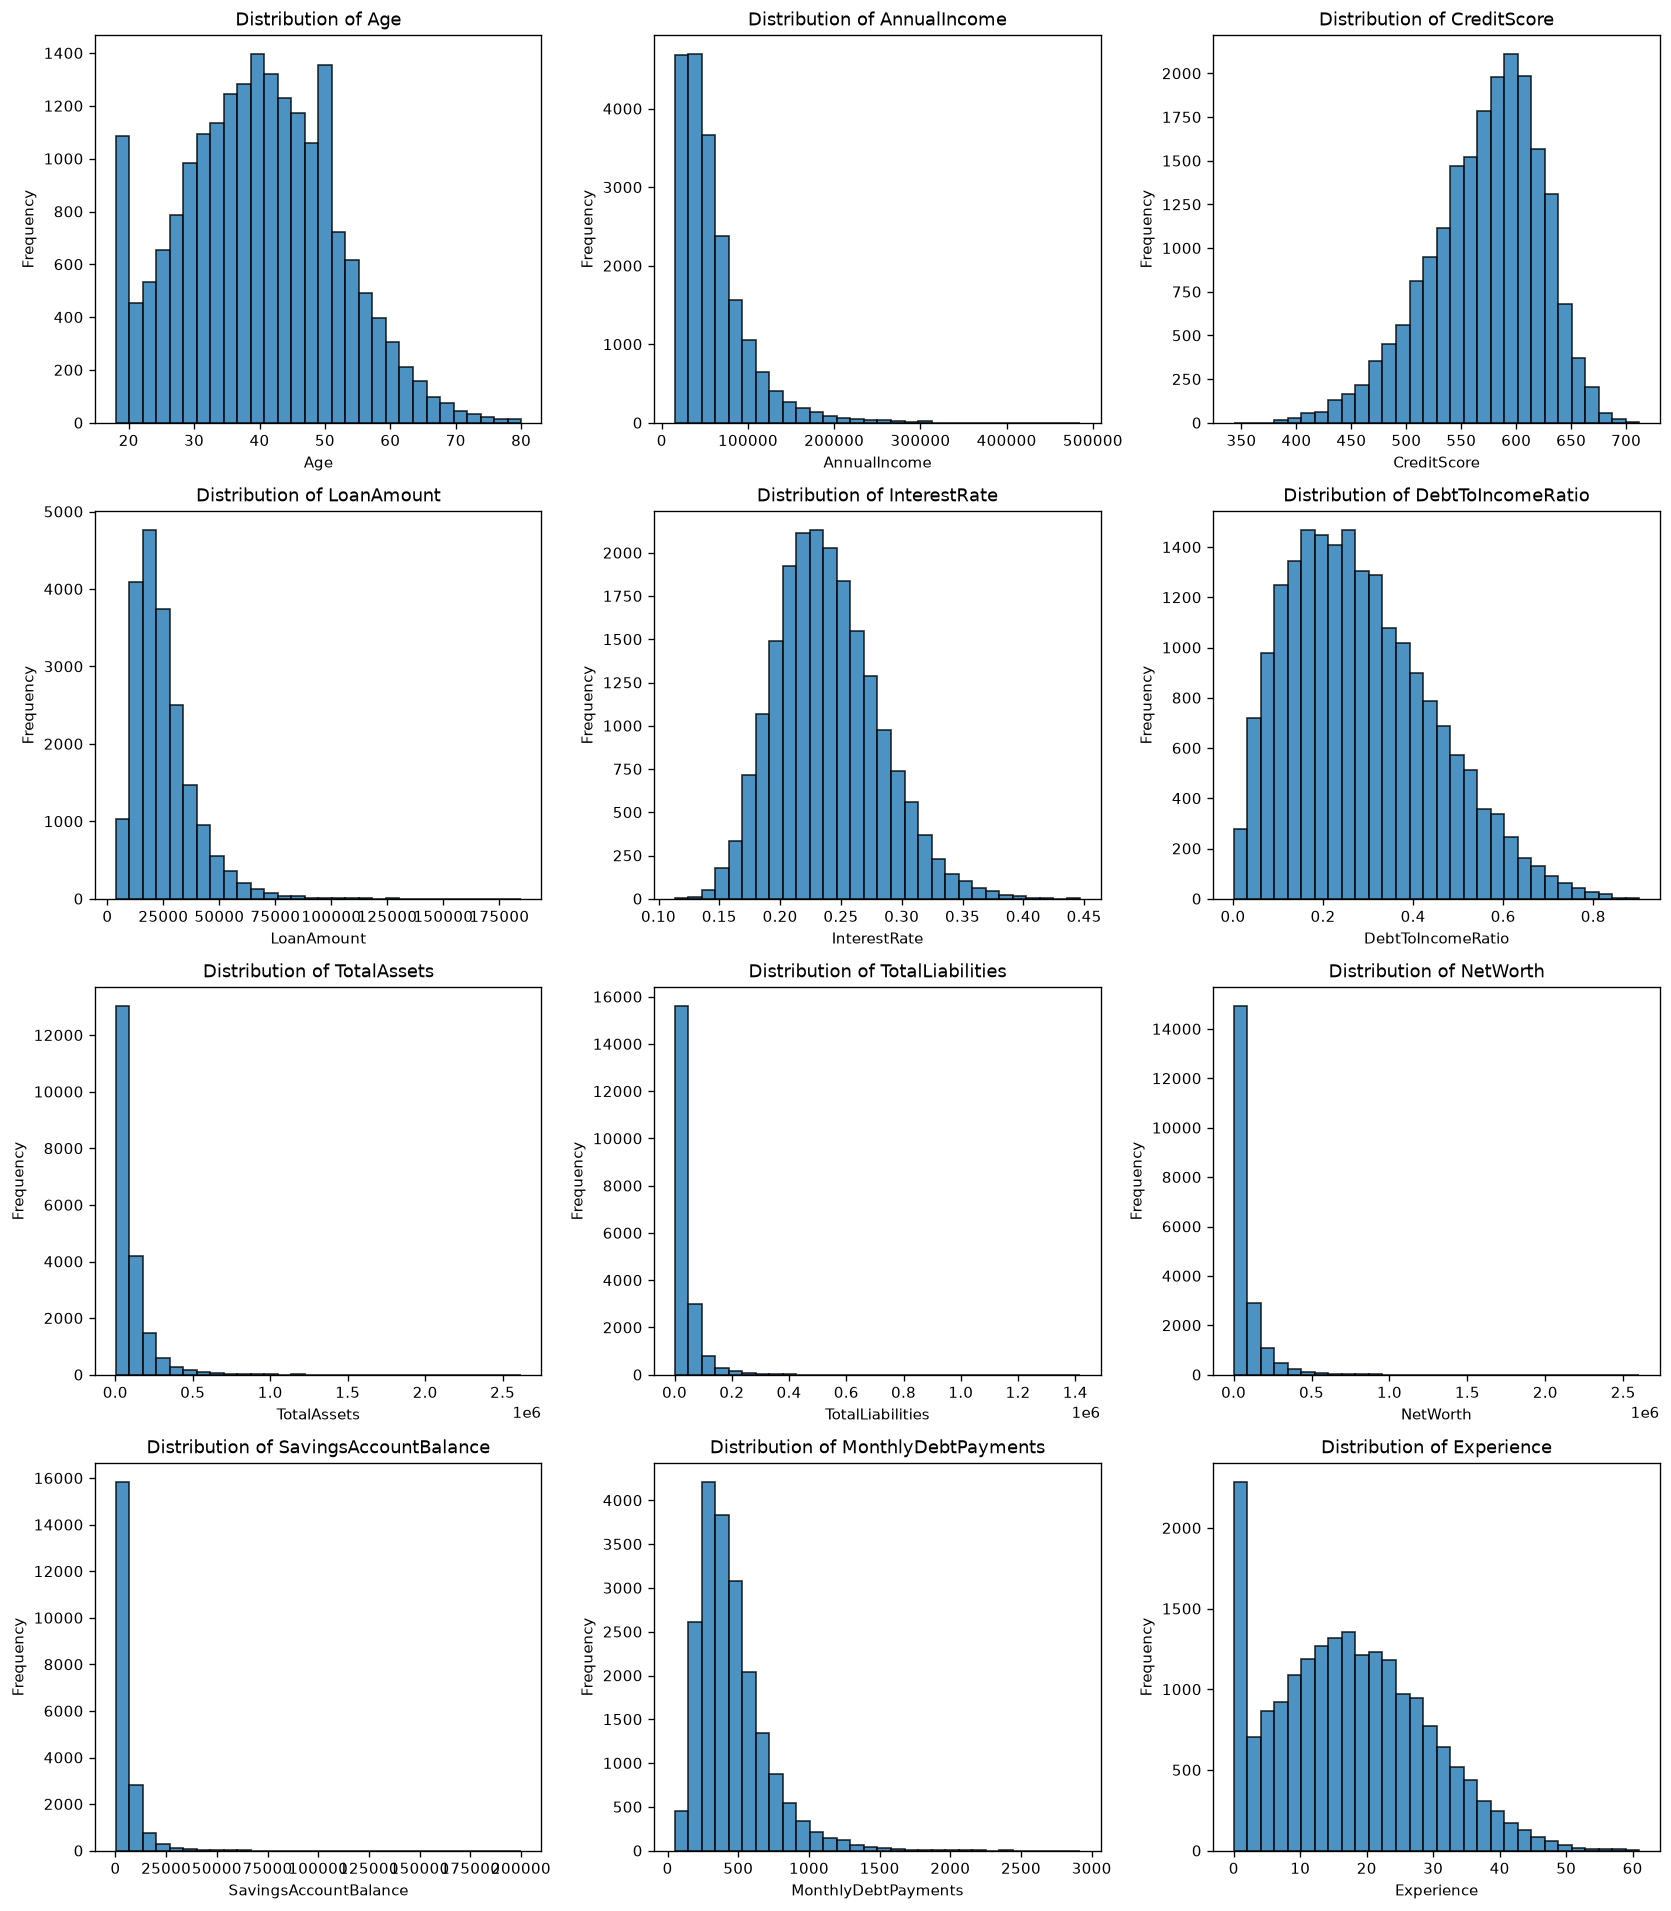

In [15]:
# ============================================================
# FIGURE 1: NUMERICAL FEATURE DISTRIBUTIONS
# ============================================================

# Select numerical features for visualization
selected_numeric = [
    "Age",
    "AnnualIncome",
    "CreditScore",
    "LoanAmount",
    "InterestRate",
    "DebtToIncomeRatio",
    "TotalAssets",
    "TotalLiabilities",
    "NetWorth",
    "SavingsAccountBalance",
    "MonthlyDebtPayments",
    "Experience"
]

# Keep only columns available in the dataset
numeric_features_eda = [
    col for col in selected_numeric
    if col in df_donor_clean.columns
]

# Create histograms
n_features = len(numeric_features_eda)
n_cols = 3
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(14, 4 * n_rows)
)

axes = np.array(axes).flatten()

for ax, column in zip(axes, numeric_features_eda):

    values = df_donor_clean[column].dropna()

    ax.hist(
        values,
        bins=30,
        edgecolor="black",
        alpha=0.8
    )

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")

# Hide unused subplot spaces
for ax in axes[n_features:]:
    ax.set_visible(False)

save_eda_figure("EDA_Figure_1_Numerical_Distributions")

### Figure 2: Outlier Analysis Using Boxplots

Figure saved: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_02_EDA\EDA_Figure_2_Numerical_Boxplots.png


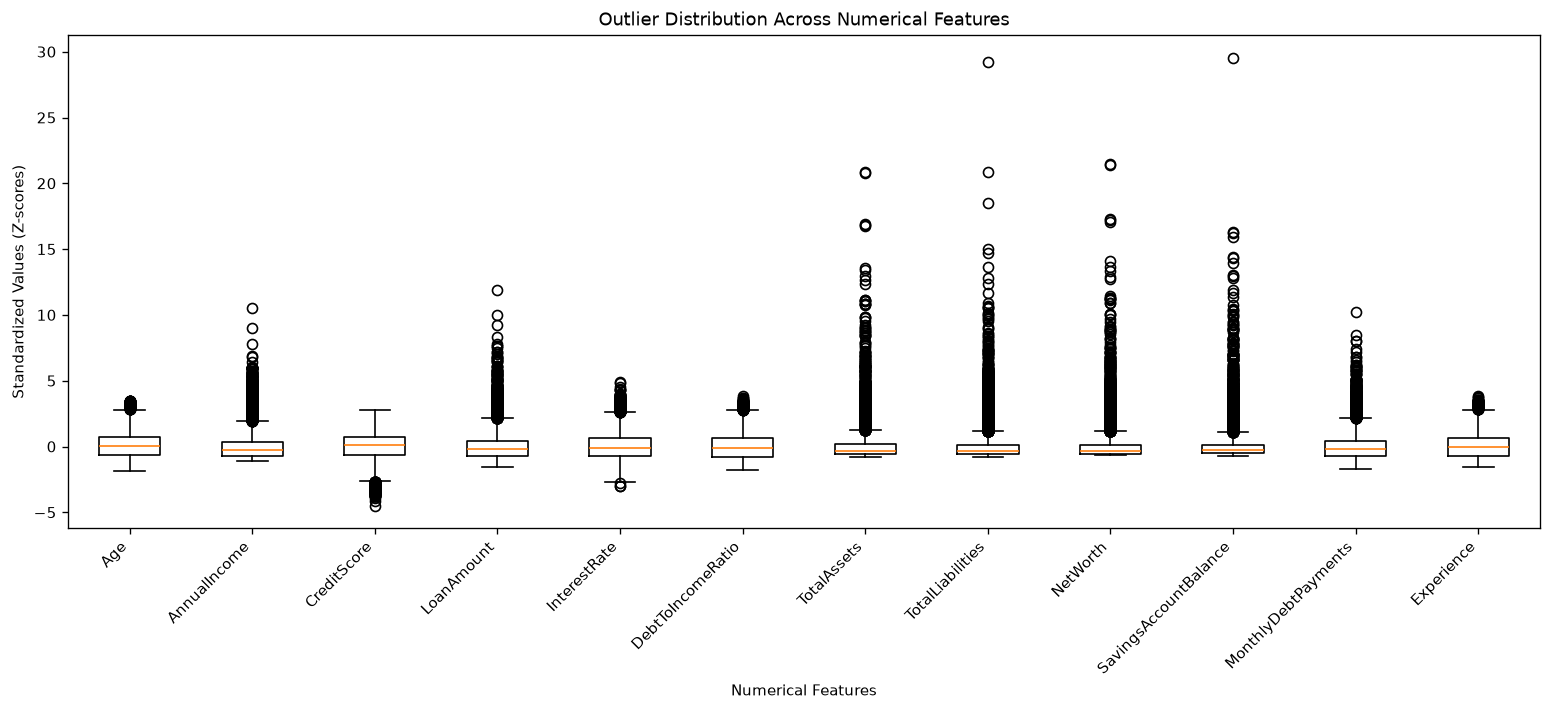

In [16]:
# ============================================================
# FIGURE 2: NUMERICAL FEATURE BOXPLOTS
# ============================================================

# Standardize numerical features for visual comparison
# because they have different measurement scales.

boxplot_data = []
boxplot_labels = []

for column in numeric_features_eda:

    values = df_donor_clean[column].dropna()

    std = values.std()

    if std > 0:

        standardized = (values - values.mean()) / std

        boxplot_data.append(standardized)
        boxplot_labels.append(column)


# Create boxplot
fig, ax = plt.subplots(figsize=(13, 6))

ax.boxplot(
    boxplot_data,
    tick_labels=boxplot_labels,
    showfliers=True
)

ax.set_title("Outlier Distribution Across Numerical Features")
ax.set_xlabel("Numerical Features")
ax.set_ylabel("Standardized Values (Z-scores)")

plt.xticks(rotation=45, ha="right")

save_eda_figure("EDA_Figure_2_Numerical_Boxplots")

Figure saved: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_02_EDA\EDA_Figure_3_Categorical_Distributions.png


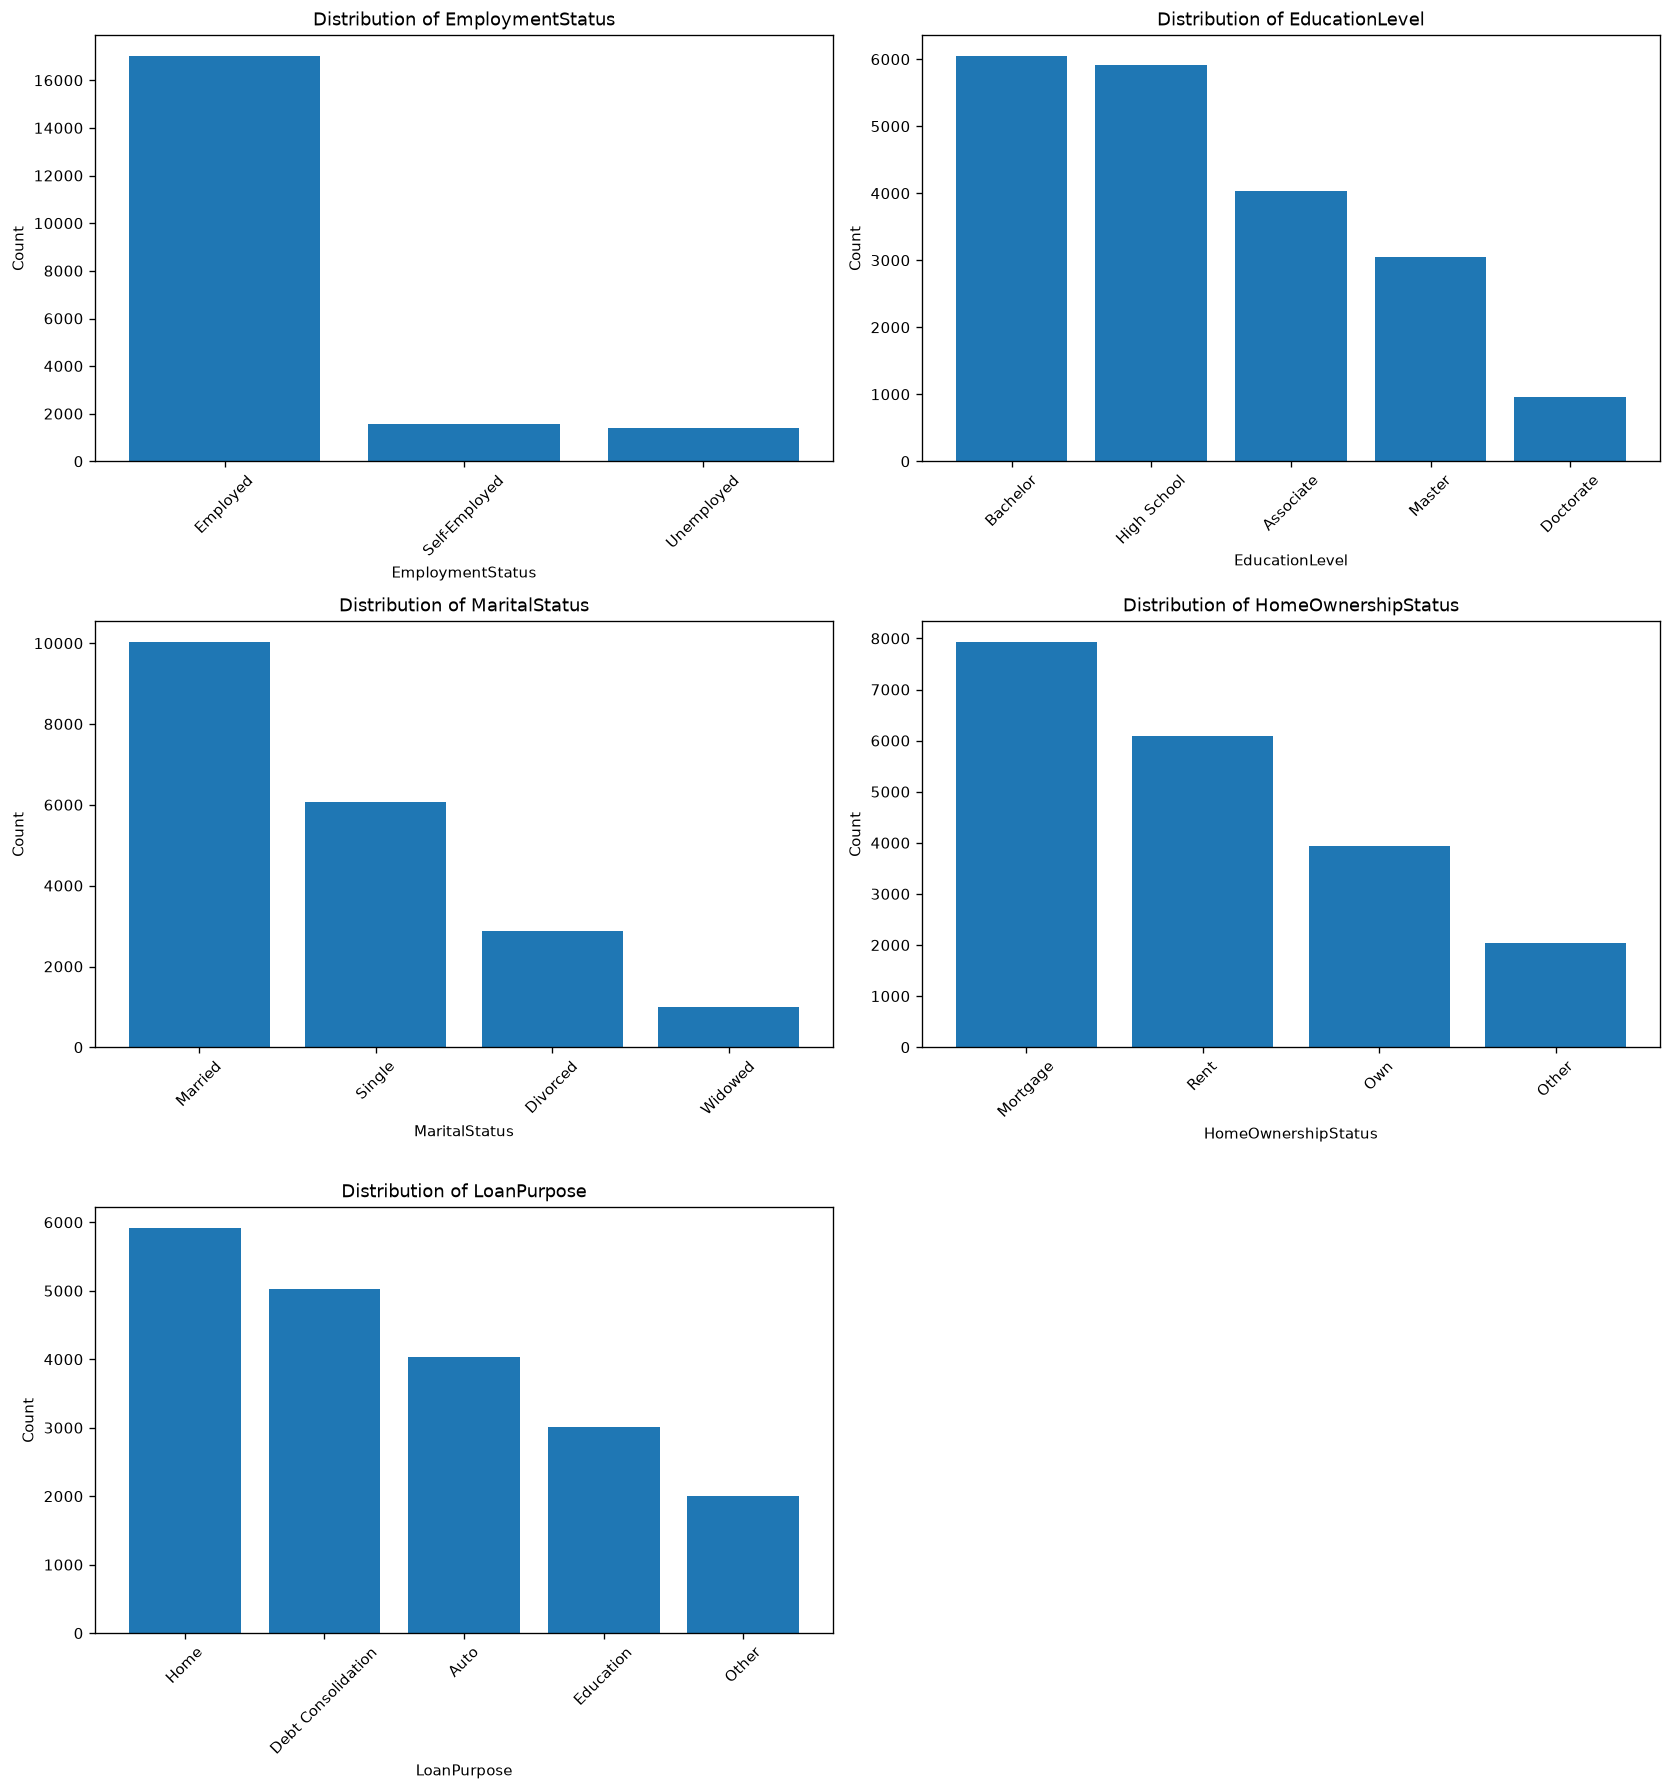

In [17]:
# FIGURE 3: CATEGORICAL FEATURE DISTRIBUTIONS

categorical_features_eda = df_donor_clean.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

# Exclude ApplicationDate because it is a date field
categorical_features_eda = [
    col for col in categorical_features_eda
    if col != "ApplicationDate"
]

n_cols = 2
n_rows = (len(categorical_features_eda) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(14, 5 * n_rows)
)

axes = np.array(axes).flatten()

for i, column in enumerate(categorical_features_eda):
    counts = df_donor_clean[column].value_counts()

    axes[i].bar(
        counts.index.astype(str),
        counts.values
    )

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis="x", rotation=45)

# Hide unused subplot spaces
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
save_eda_figure("EDA_Figure_3_Categorical_Distributions")

Figure saved: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_02_EDA\EDA_Figure_4_Correlation_Heatmap.png


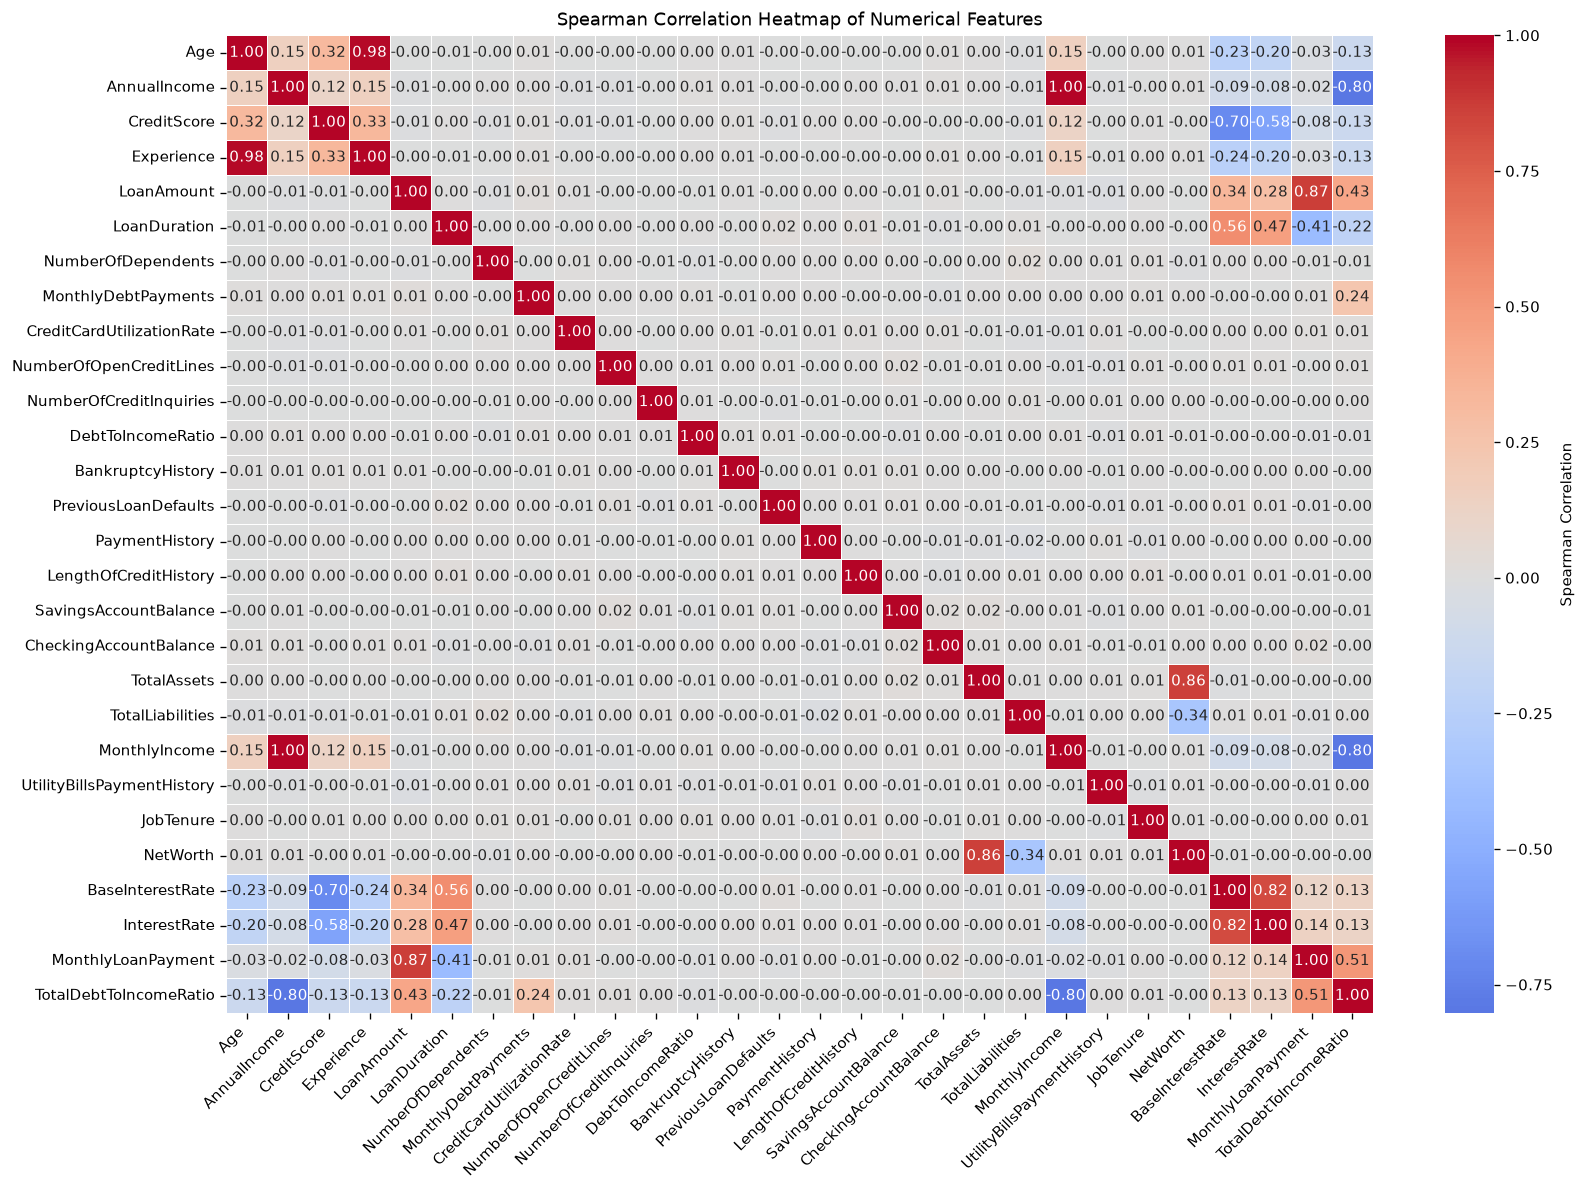

In [18]:
# FIGURE 4: SPEARMAN CORRELATION HEATMAP

import seaborn as sns

fig, ax = plt.subplots(figsize=(14, 10))

sns.heatmap(
    donor_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Spearman Correlation"},
    ax=ax
)

ax.set_title("Spearman Correlation Heatmap of Numerical Features")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
save_eda_figure("EDA_Figure_4_Correlation_Heatmap")

Figure saved: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_02_EDA\EDA_Figure_5_Financial_Relationships.png


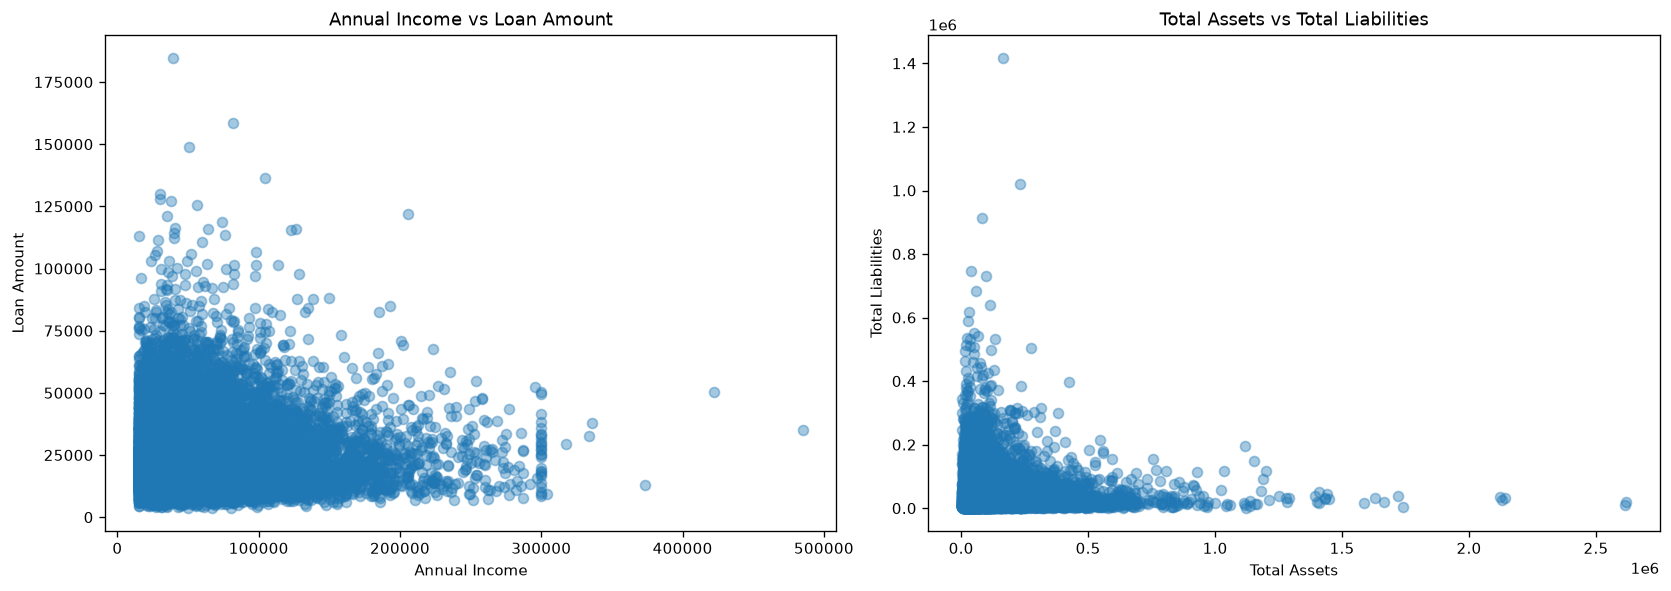

In [19]:
# FIGURE 5: FINANCIAL RELATIONSHIP SCATTER PLOTS

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Annual Income vs Loan Amount
axes[0].scatter(
    df_donor_clean["AnnualIncome"],
    df_donor_clean["LoanAmount"],
    alpha=0.4
)
axes[0].set_title("Annual Income vs Loan Amount")
axes[0].set_xlabel("Annual Income")
axes[0].set_ylabel("Loan Amount")

# Total Assets vs Total Liabilities
axes[1].scatter(
    df_donor_clean["TotalAssets"],
    df_donor_clean["TotalLiabilities"],
    alpha=0.4
)
axes[1].set_title("Total Assets vs Total Liabilities")
axes[1].set_xlabel("Total Assets")
axes[1].set_ylabel("Total Liabilities")

plt.tight_layout()
save_eda_figure("EDA_Figure_5_Financial_Relationships")

Figure saved: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_02_EDA\EDA_Figure_6_Approval_RiskScore.png


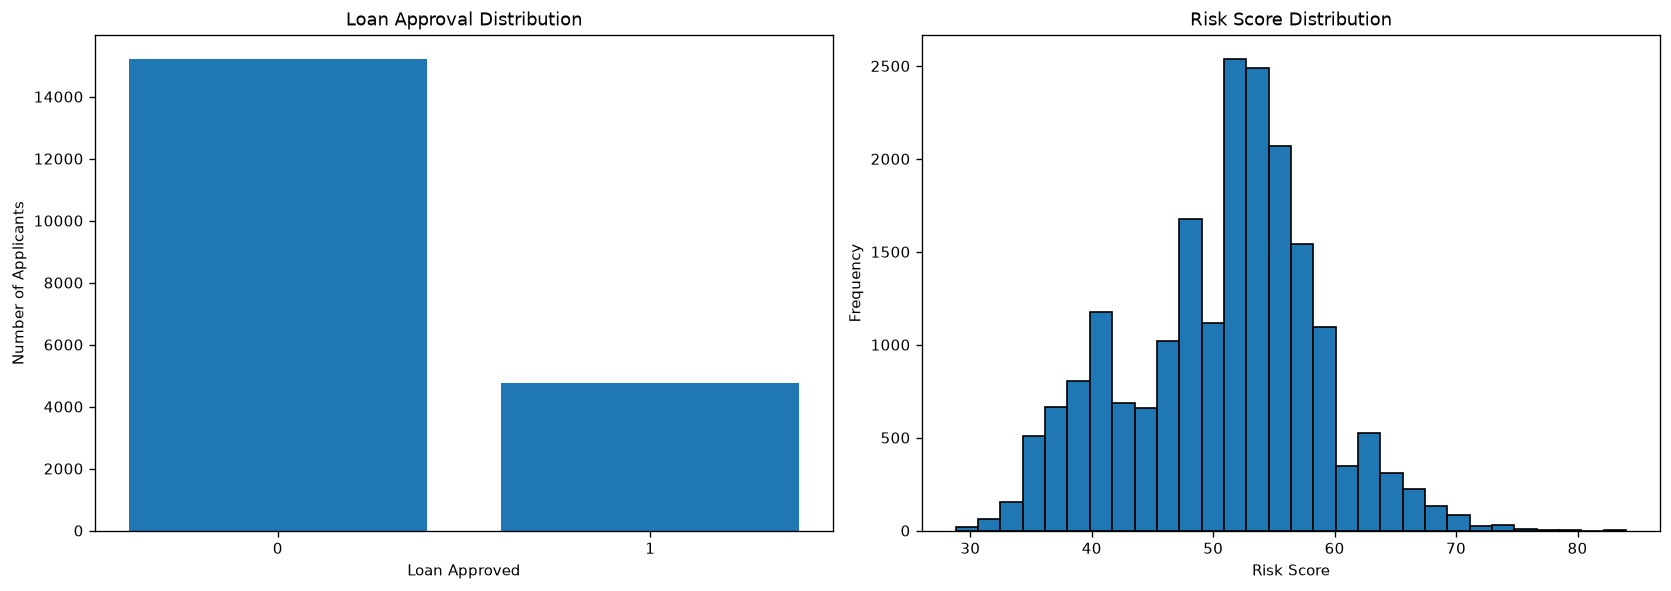

In [20]:
# FIGURE 6: LOAN APPROVAL AND RISK SCORE DISTRIBUTIONS

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loan Approval Distribution
approval_counts = df_donor_clean["LoanApproved"].value_counts().sort_index()

axes[0].bar(
    approval_counts.index.astype(str),
    approval_counts.values
)

axes[0].set_title("Loan Approval Distribution")
axes[0].set_xlabel("Loan Approved")
axes[0].set_ylabel("Number of Applicants")

# Risk Score Distribution
axes[1].hist(
    df_donor_clean["RiskScore"].dropna(),
    bins=30,
    edgecolor="black"
)

axes[1].set_title("Risk Score Distribution")
axes[1].set_xlabel("Risk Score")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
save_eda_figure("EDA_Figure_6_Approval_RiskScore")

In [21]:
# Save inspected donor dataset

processed_dir = project_dir / "datasets" / "processed"

processed_dir.mkdir(
    parents=True,
    exist_ok=True
)

donor_output_path = (
    processed_dir / "financial_risk_inspected.csv"
)

df_donor_clean.to_csv(
    donor_output_path,
    index=False
)

print("Donor dataset saved successfully!")
print("Location:", donor_output_path)
print("Shape:", df_donor_clean.shape)
print("Missing values:", df_donor_clean.isnull().sum().sum())
print("Duplicate rows:", df_donor_clean.duplicated().sum())

Donor dataset saved successfully!
Location: D:\AI-Engineering\Loan_Default_Research\datasets\processed\financial_risk_inspected.csv
Shape: (20000, 36)
Missing values: 0
Duplicate rows: 0


## Summary of Financial Risk Dataset Inspection

The Financial Risk dataset contains 20,000 records and 36 features. The initial inspection identified no missing values or exact duplicate records.

Several data-quality concerns were observed. Job tenure exceeds total work experience in 3,098 records (15.49%), while annual and monthly income differ beyond the selected tolerance in 195 records. Net worth differs from the calculated value of total assets minus total liabilities in 4,801 records.

The ApplicationDate column contains 20,000 unique consecutive daily dates, extending from 2018 to 2072. This pattern suggests that the dates may be artificially generated and should not be interpreted as genuine application timing.

Potential outliers were identified using the IQR method. These observations were retained because statistical outliers are not necessarily erroneous values.

The dataset is treated as a donor dataset for statistical data fusion. Its LoanApproved variable is not used as the prediction target. The Credit Risk dataset's loan_status variable remains the target for loan default prediction.

The inspection findings will guide the selection of donor features for the subsequent statistical matching procedure. No records were removed or modified during this inspection stage.